1 — Paths + checkpoint

In [1]:
import os, sys, json
from pathlib import Path

import torch
from torch.utils.data import DataLoader
from torchvision import transforms

# Paths
R2GEN_DIR = Path("/home/psivakumar/thesis/code/R2GenCMN")
ANN_PATH  = Path("/home/psivakumar/thesis/data/iu_xray/annotation_r2gencmn_2view_r2gencmnformat.json")
IMG_DIR   = R2GEN_DIR / "data" / "iu_xray"   # root that contains images/

CKPT_5EP  = R2GEN_DIR / "outputs" / "iu_xray_r2gencmn_baseline_5ep" / "current_checkpoint.pth"
CKPT_10EP = R2GEN_DIR / "outputs" / "final_r2gencmn_10ep" / "current_checkpoint.pth"

assert R2GEN_DIR.exists(), "R2GenCMN repo not found"
assert ANN_PATH.exists(), "Annotation JSON not found"
assert IMG_DIR.exists(), "IMG_DIR not found"
assert CKPT_5EP.exists(), "CKPT_5EP not found"
assert CKPT_10EP.exists(), "CKPT_10EP not found"

# Make repo importable
os.chdir(R2GEN_DIR)
if str(R2GEN_DIR) not in sys.path:
    sys.path.insert(0, str(R2GEN_DIR))

print("CWD:", os.getcwd())
print("Repo import OK")
print("CKPT_5EP :", CKPT_5EP)
print("CKPT_10EP:", CKPT_10EP)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE:", DEVICE)

CWD: /home/psivakumar/thesis/code/R2GenCMN
Repo import OK
CKPT_5EP : /home/psivakumar/thesis/code/R2GenCMN/outputs/iu_xray_r2gencmn_baseline_5ep/current_checkpoint.pth
CKPT_10EP: /home/psivakumar/thesis/code/R2GenCMN/outputs/final_r2gencmn_10ep/current_checkpoint.pth
DEVICE: cuda


2 — Build args correctly (important: includes required fields)

In [2]:
class Args: 
    pass

args = Args()

# core
args.dataset_name = "iu_xray"
args.image_dir = str(IMG_DIR)
args.ann_path  = str(ANN_PATH)

# tokenizer / seq
args.threshold = 3
args.max_seq_length = 100

# visual extractor
args.visual_extractor = "resnet101"
args.visual_extractor_pretrained = True

# model sizes
args.num_layers = 3
args.d_model = 512
args.d_ff = 512
args.num_heads = 8
args.d_vf = 2048

# dropout knobs
args.drop_prob_lm = 0.1
args.dropout = 0.1

# cmn / memory
args.topk = 32
args.cmm_size = 2048
args.cmm_dim  = 512

# misc flags required inside AttModel
args.use_bn = 0

print("Args ready")

Args ready


3 — Load tokenizer + fix special token indices

In [3]:
from modules.tokenizers import Tokenizer

tokenizer = Tokenizer(args)

args.pad_idx = 0
args.bos_idx = 0
args.eos_idx = 0

args.unk_idx = tokenizer.token2idx.get("<unk>", None)

print("Tokenizer vocab size:", tokenizer.get_vocab_size())
print("pad_idx:", args.pad_idx, "bos_idx:", args.bos_idx, "eos_idx:", args.eos_idx, "unk_idx:", args.unk_idx)

Tokenizer vocab size: 928
pad_idx: 0 bos_idx: 0 eos_idx: 0 unk_idx: 27


4 — Dataset + collate_fn (this fixes your crash)

In [4]:
from modules.datasets import IuxrayMultiImageDataset

img_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

dataset = IuxrayMultiImageDataset(args=args, tokenizer=tokenizer, split="test", transform=img_transform)

def r2gencmn_collate_fn(batch, pad_idx=0):
    image_ids, images, report_ids, report_masks, seq_lengths = zip(*batch)

    images = torch.stack(images, dim=0)  # [B, 2, 3, H, W]

    max_len = max(len(x) for x in report_ids)

    report_ids_pad = torch.full((len(batch), max_len), pad_idx, dtype=torch.long)
    report_masks_pad = torch.zeros((len(batch), max_len), dtype=torch.long)

    for i, (ids, msk) in enumerate(zip(report_ids, report_masks)):
        ids_t = torch.tensor(ids, dtype=torch.long)
        msk_t = torch.tensor(msk, dtype=torch.long)
        report_ids_pad[i, :len(ids_t)] = ids_t
        report_masks_pad[i, :len(msk_t)] = msk_t

    seq_lengths = torch.tensor(seq_lengths, dtype=torch.long)
    return list(image_ids), images, report_ids_pad, report_masks_pad, seq_lengths

loader = DataLoader(
    dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,  # stable
    collate_fn=lambda b: r2gencmn_collate_fn(b, pad_idx=args.pad_idx)
)

# sanity check
b = next(iter(loader))
print("Batch ok ✅")
print("images:", b[1].shape, "| report_ids:", b[2].shape)
print("first uid:", b[0][0])

Batch ok ✅
images: torch.Size([4, 2, 3, 224, 224]) | report_ids: torch.Size([4, 71])
first uid: 1623


5 — Build model + load checkpoint (works for both 5ep and 10ep)

In [5]:
from models.models import BaseCMNModel

def load_model_from_ckpt(ckpt_path: Path):
    model = BaseCMNModel(args, tokenizer).to(DEVICE)
    ckpt = torch.load(str(ckpt_path), map_location=DEVICE)
    state_dict = ckpt["state_dict"] if isinstance(ckpt, dict) and "state_dict" in ckpt else ckpt
    model.load_state_dict(state_dict, strict=False)
    model.eval()
    return model

print("Model loader ready")

Model loader ready


6 — Generate predictions for a checkpoint

In [6]:
def generate_preds_for_ckpt(ckpt_path: Path, max_batches=None):
    model = load_model_from_ckpt(ckpt_path)

    rows = []
    with torch.no_grad():
        for bi, batch in enumerate(loader):
            if max_batches is not None and bi >= max_batches:
                break

            image_ids, images, report_ids, report_masks, seq_lengths = batch
            images = images.to(DEVICE)

            out = model(images, mode="sample")
            out_ids = out[0] if isinstance(out, (tuple, list)) else out  # <-- important

            preds = tokenizer.decode_batch(out_ids.cpu().numpy())
            gts   = tokenizer.decode_batch(report_ids[:, 1:].cpu().numpy())

            for uid, gt, pr in zip(image_ids, gts, preds):
                rows.append({"uid": str(uid), "gt": gt, "pred": pr})

    return rows

print("Prediction function ready")

Prediction function ready


7 — Run both checkpoints + save json

In [7]:
preds_5ep  = generate_preds_for_ckpt(CKPT_5EP)
preds_10ep = generate_preds_for_ckpt(CKPT_10EP)

print("5ep preds :", len(preds_5ep))
print("10ep preds:", len(preds_10ep))

OUTDIR = Path("/home/psivakumar/thesis/notebooks/runs/r2gencmn_compare")
OUTDIR.mkdir(parents=True, exist_ok=True)

p5 = OUTDIR / "preds_test_5ep.json"
p10 = OUTDIR / "preds_test_10ep.json"

json.dump(preds_5ep, open(p5, "w"), indent=2)
json.dump(preds_10ep, open(p10, "w"), indent=2)

print("Saved")
print(" -", p5)
print(" -", p10)

/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet101_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet101_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/torch/cuda/__init__.py:716: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/tmp/ipykernel_605602/3884414463.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle mo

5ep preds : 44
10ep preds: 44
Saved
 - /home/psivakumar/thesis/notebooks/runs/r2gencmn_compare/preds_test_5ep.json
 - /home/psivakumar/thesis/notebooks/runs/r2gencmn_compare/preds_test_10ep.json


8 — Evaluate ROUGE-L mean (simple, no extra libraries)

In [8]:
def lcs_len(a, b):
    # a, b are token lists
    n, m = len(a), len(b)
    dp = [0]*(m+1)
    for i in range(1, n+1):
        prev = 0
        for j in range(1, m+1):
            tmp = dp[j]
            if a[i-1] == b[j-1]:
                dp[j] = prev + 1
            else:
                dp[j] = max(dp[j], dp[j-1])
            prev = tmp
    return dp[m]

def rougeL_f1(gt, pr):
    gt_t = gt.split()
    pr_t = pr.split()
    if len(gt_t) == 0 or len(pr_t) == 0:
        return 0.0
    l = lcs_len(gt_t, pr_t)
    r = l / len(gt_t)
    p = l / len(pr_t)
    if (r + p) == 0:
        return 0.0
    return 2*r*p/(r+p)

def mean_rougeL(rows):
    vals = [rougeL_f1(r["gt"], r["pred"]) for r in rows]
    return sum(vals)/len(vals), vals

m5, vals5 = mean_rougeL(preds_5ep)
m10, vals10 = mean_rougeL(preds_10ep)

print("ROUGE-L mean 5ep :", m5)
print("ROUGE-L mean 10ep:", m10)

ROUGE-L mean 5ep : 0.3518737233734858
ROUGE-L mean 10ep: 0.3320859391162359


9 — Visualization: histogram of ROUGE-L for 5ep vs 10ep

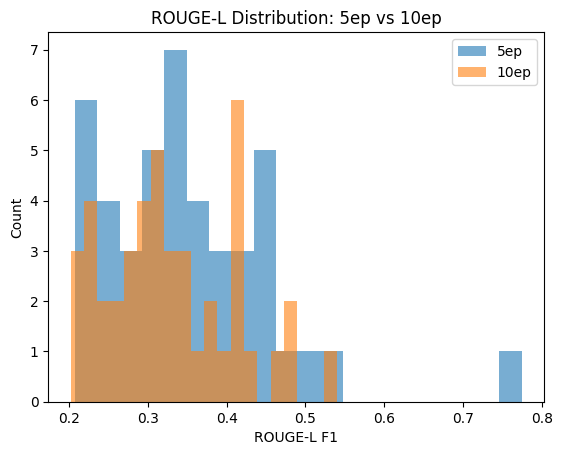

In [9]:
import matplotlib.pyplot as plt

plt.figure()
plt.hist(vals5, bins=20, alpha=0.6, label="5ep")
plt.hist(vals10, bins=20, alpha=0.6, label="10ep")
plt.xlabel("ROUGE-L F1")
plt.ylabel("Count")
plt.title("ROUGE-L Distribution: 5ep vs 10ep")
plt.legend()
plt.show()

10 — Show qualitative examples where 10ep improved most

In [10]:
diffs = []
for r5, r10 in zip(preds_5ep, preds_10ep):
    assert r5["uid"] == r10["uid"]
    s5 = rougeL_f1(r5["gt"], r5["pred"])
    s10 = rougeL_f1(r10["gt"], r10["pred"])
    diffs.append((s10 - s5, r5["uid"], r5["gt"], r5["pred"], r10["pred"], s5, s10))

diffs.sort(reverse=True)

print("Top 5 where 10ep improved most:\n")
for d, uid, gt, p5, p10, s5, s10 in diffs[:5]:
    print("="*90)
    print("UID:", uid, "| Δ:", round(d,4), "| 5ep:", round(s5,3), "| 10ep:", round(s10,3))
    print("GT :", gt[:250])
    print("5ep:", p5[:250])
    print("10ep:", p10[:250])

Top 5 where 10ep improved most:

UID: 1199 | Δ: 0.1466 | 5ep: 0.394 | 10ep: 0.541
GT : the cardiomediastinal silhouette is within normal limits . the lungs are well expanded without consolidation or edema . no pneumothorax or pleural effusion . visualized osseous structures are unremarkable . impression no radiographic evidence of acti
5ep: the heart is normal in size . the mediastinum is stable . the aorta is atherosclerotic . the lungs are clear . impression no acute disease .
10ep: the heart size and pulmonary vascularity appear within normal limits . the lungs are free of focal airspace disease . no pleural effusion or pneumothorax is seen . impression no evidence of active disease .
UID: 916 | Δ: 0.1165 | 5ep: 0.208 | 10ep: 0.324
GT : lungs are clear without focal airspace disease . numerous xxxx calcifications are again noted . no pleural effusions or pneumothoraces . heart size is upper limits of normal . impression clear lungs with heart size upper limits of normal .
5ep: the h

Diversity Comparison

In [11]:
def pred_stats(rows):
    preds = [r["pred"].strip() for r in rows]
    uniq = len(set(preds))
    total = len(preds)
    return {
        "total": total,
        "unique": uniq,
        "diversity_ratio": uniq/total,
        "top_pred_count": max([preds.count(p) for p in set(preds)])
    }

s5 = pred_stats(preds_5ep)
s10 = pred_stats(preds_10ep)

print("5ep stats :", s5)
print("10ep stats:", s10)

5ep stats : {'total': 44, 'unique': 5, 'diversity_ratio': 0.11363636363636363, 'top_pred_count': 17}
10ep stats: {'total': 44, 'unique': 3, 'diversity_ratio': 0.06818181818181818, 'top_pred_count': 29}


Balanced Score

In [12]:
balanced_5 = m5 * s5["diversity_ratio"]
balanced_10 = m10 * s10["diversity_ratio"]

print("Balanced score 5ep :", balanced_5)
print("Balanced score 10ep:", balanced_10)

Balanced score 5ep : 0.03998565038335066
Balanced score 10ep: 0.022642223121561538


C — Plot top prediction dominance (quick visual)

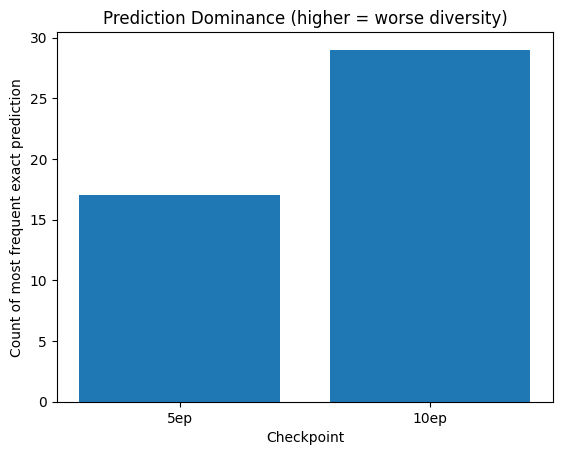

In [13]:
import matplotlib.pyplot as plt

plt.figure()
plt.bar(["5ep", "10ep"], [s5["top_pred_count"], s10["top_pred_count"]])
plt.xlabel("Checkpoint")
plt.ylabel("Count of most frequent exact prediction")
plt.title("Prediction Dominance (higher = worse diversity)")
plt.show()

Random UID: 2462
Image paths: [PosixPath('/home/psivakumar/thesis/code/R2GenCMN/data/iu_xray/images/2462_IM-0995-1001.dcm.png'), PosixPath('/home/psivakumar/thesis/code/R2GenCMN/data/iu_xray/images/2462_IM-0995-3001.dcm.png')]


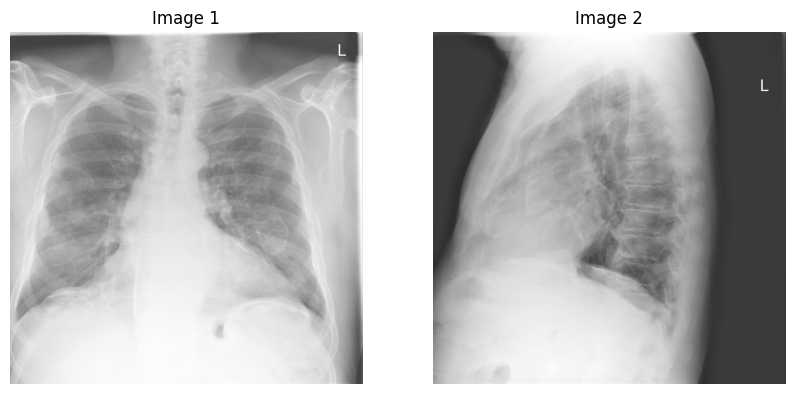

/tmp/ipykernel_605602/1450074667.py:52: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(str(CKPT_PATH), map_location="cpu")


Inferred from checkpoint: cmm_size=2048, cmm_dim=512


/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet101_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet101_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


✅ Loaded checkpoint
Missing keys: 0
Unexpected keys: 0

GT REPORT:
 There is stable cardiomegaly. Aorta is calcified and tortuous. There are multiple pleural calcifications XXXX representing prior asbestos exposure. These appear unchanged. There is no pneumothorax, pleural effusion, or XXXX focal airspace consolidation. IMPRESSION: 1. Cardiomegaly and findings of prior asbestos exposure without interval acute cardiopulmonary findings.

------------------------------------------------------------------------------------------
PRED REPORT:
 the heart size and pulmonary vascularity appear within normal limits . the lungs are free of focal airspace disease . no pleural effusion or pneumothorax is seen . impression no evidence of active disease .


In [14]:
import json, random, sys
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms

ANN_PATH  = Path("/home/psivakumar/thesis/data/iu_xray/annotation_r2gencmn_2view_r2gencmnformat.json")
IMG_DIR   = Path("/home/psivakumar/thesis/code/R2GenCMN/data/iu_xray")
CKPT_PATH = Path("/home/psivakumar/thesis/code/R2GenCMN/outputs/final_r2gencmn_10ep/current_checkpoint.pth")
REPO_DIR  = Path("/home/psivakumar/thesis/code/R2GenCMN")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

sys.path.insert(0, str(REPO_DIR))
from modules.tokenizers import Tokenizer
from models.models import BaseCMNModel

ann = json.loads(ANN_PATH.read_text())
test_list = ann["test"]

candidates = [e for e in test_list if len(e["report"].split()) > 35]
candidates = [e for e in test_list if len(e["report"].split()) > 40]
ex = random.choice(candidates if candidates else test_list)

uid = ex["id"]
gt_report = ex["report"]
img_paths = [IMG_DIR / p for p in ex["image_path"]]

print("Random UID:", uid)
print("Image paths:", img_paths)

imgs_pil = [Image.open(p).convert("RGB") for p in img_paths]

plt.figure(figsize=(10, 5))
for i, im in enumerate(imgs_pil):
    plt.subplot(1, 2, i+1)
    plt.imshow(im)
    plt.axis("off")
    plt.title("Image 1" if i == 0 else "Image 2")
plt.show()

tfm = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

x = torch.stack([tfm(im) for im in imgs_pil], dim=0).unsqueeze(0).to(DEVICE)

ckpt = torch.load(str(CKPT_PATH), map_location="cpu")
state_dict = ckpt["state_dict"] if isinstance(ckpt, dict) and "state_dict" in ckpt else ckpt

mm = state_dict.get("encoder_decoder.memory_matrix", None)
assert mm is not None, "Could not find encoder_decoder.memory_matrix in checkpoint!"
cmm_size, cmm_dim = mm.shape
print(f"Inferred from checkpoint: cmm_size={cmm_size}, cmm_dim={cmm_dim}")

class Args: pass
args = Args()
args.dataset_name = "iu_xray"
args.ann_path = str(ANN_PATH)
args.image_dir = str(IMG_DIR)
args.max_seq_length = 100
args.threshold = 3

args.visual_extractor = "resnet101"
args.visual_extractor_pretrained = True

args.num_layers = 3
args.num_heads = 8
args.d_model = 512
args.d_ff = 512
args.d_vf = 2048
args.dropout = 0.1
args.drop_prob_lm = 0.1
args.use_bn = 0

args.topk = 32
args.cmm_size = int(cmm_size)
args.cmm_dim  = int(cmm_dim) 

args.pad_idx = 0
args.bos_idx = 0
args.eos_idx = 0
args.unk_idx = 0

tokenizer = Tokenizer(args)
model = BaseCMNModel(args, tokenizer).to(DEVICE)

missing, unexpected = model.load_state_dict(state_dict, strict=False)
print("✅ Loaded checkpoint")
print("Missing keys:", len(missing))
print("Unexpected keys:", len(unexpected))

model.eval()

with torch.no_grad():
    out = model(x, mode="sample")
    tokens = out[0] if isinstance(out, (tuple, list)) else out
    pred_report = tokenizer.decode_batch(tokens.detach().cpu().numpy())[0]

print("\n" + "="*90)
print("GT REPORT:\n", gt_report)
print("\n" + "-"*90)
print("PRED REPORT:\n", pred_report)
print("="*90)